# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/hotels.csv'
df = pd.read_csv(url)

display(df.head())
df.describe()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection: 
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The first two rows have an adr of 0, so those guests paid nothing per night, which seems wrong. One of them also has a lead time of 737 days, so they booked about two years ahead. The summary stats have some weird max values too, like 55 adults on one booking and 33 week nights. The agent and company columns have a lot of blanks.


## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
from sklearn.preprocessing import StandardScaler

features = ['lead_time', 'stays_in_week_nights', 'adr', 'total_of_special_requests']

df = df.drop_duplicates()
df = df[df['adr'].between(1, 500)]
df = df[df['lead_time'] <= 365]
df = df[df['stays_in_week_nights'] <= 14]
df = df.dropna(subset=features)
print(df[features].dtypes)

scaler = StandardScaler()
scaled = scaler.fit_transform(df[features])

lead_time                      int64
stays_in_week_nights           int64
adr                          float64
total_of_special_requests      int64
dtype: object


### Reflection: 
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I picked lead_time, stays_in_week_nights, adr, and total_of_special_requests. They cover how early someone books, how long they stay, how much they pay, and how picky they are, which is what a hotel would care about. I took out rows with an adr of 0 or over 500, lead times over a year, and stays over 14 week nights, since those looked like mistakes or rare cases.

2. I think there will be a group of last minute, short stays, and a group of people who plan way ahead for long vacations. There will probably also be a group that pays a lot more per night.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

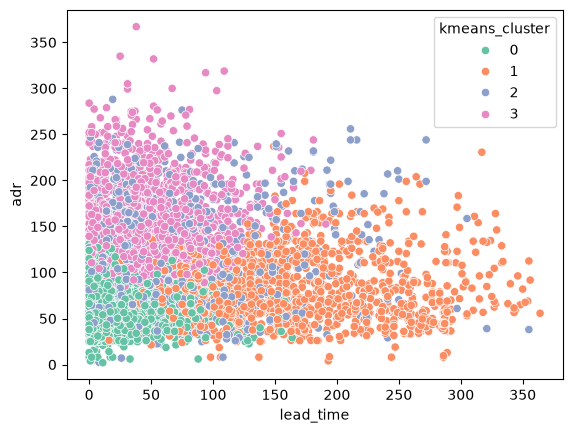

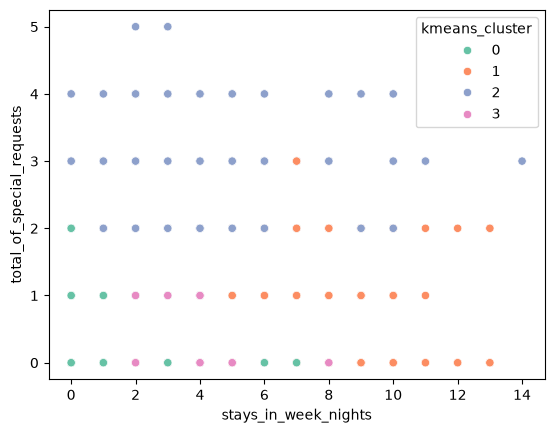

,lead_time,stays_in_week_nights,adr,total_of_special_requests
kmeans_cluster,,,,
0,18.360437,1.708234,55.638131,0.326956
1,166.631783,5.385659,78.757267,0.455426
2,63.225458,3.259567,113.900724,2.256240
3,49.552164,3.528857,154.360161,0.444506


In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=1)
df['kmeans_cluster'] = kmeans.fit_predict(scaled)

sns.scatterplot(data=df, x='lead_time', y='adr', hue='kmeans_cluster', palette='Set2')
plt.show()
sns.scatterplot(data=df, x='stays_in_week_nights', y='total_of_special_requests', hue='kmeans_cluster', palette='Set2')
plt.show()

df.groupby('kmeans_cluster')[features].mean()

### Reflection: 
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I picked k = 4. I tried 2 through 6 and 4 had the highest silhouette score (about 0.31). Four groups is also a small enough number to give each one a name.

2.
- Cluster 0: Last minute, short, cheap stays. They book about 18 days out, stay about 2 week nights, and pay about 56 a night. Lead time and adr stand out. This is the biggest group.
- Cluster 1: Planners. They book about 167 days ahead and stay the longest (about 5 week nights) at a lower rate of about 79. Lead time is the main thing here.
- Cluster 2: Guests with special requests. They average about 2.3 requests, way more than the other groups, and pay about 114 a night.
- Cluster 3: High spenders. They pay about 154 a night, the most of any group, and book about 50 days out. adr is what stands out.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

[[0.47 0.01 0.01 0.51]
 [0.   0.01 0.01 0.97]
 [0.   0.01 0.15 0.85]
 [0.   0.01 0.02 0.97]
 [0.   0.01 0.16 0.83]]


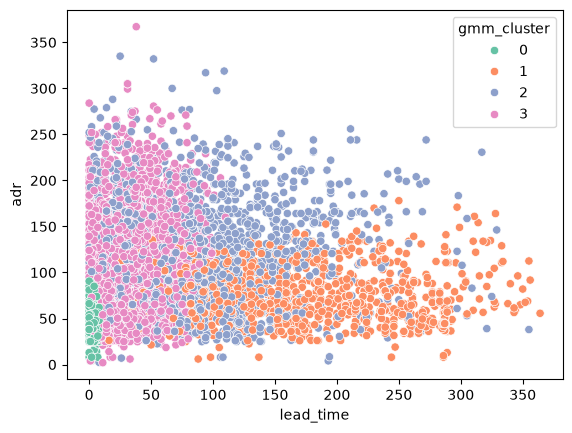

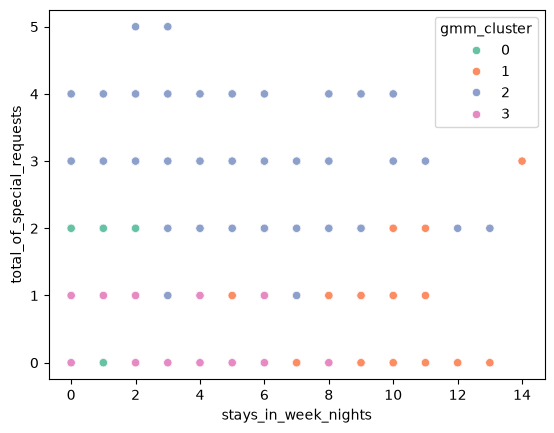

,lead_time,stays_in_week_nights,adr,total_of_special_requests
gmm_cluster,,,,
0,1.997386,1.133333,47.178693,0.398693
1,169.756672,5.195447,73.853265,0.250392
2,89.004388,3.640154,120.637559,1.777290
3,33.448808,3.024194,109.971953,0.352735


In [4]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=4, random_state=1)
df['gmm_cluster'] = gmm.fit_predict(scaled)
probs = gmm.predict_proba(scaled)
print(probs[:5].round(2))

sns.scatterplot(data=df, x='lead_time', y='adr', hue='gmm_cluster', palette='Set2')
plt.show()
sns.scatterplot(data=df, x='stays_in_week_nights', y='total_of_special_requests', hue='gmm_cluster', palette='Set2')
plt.show()

df.groupby('gmm_cluster')[features].mean()

### Reflection: 
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. They found pretty similar groups. Both had a far ahead planner group (about 170 days) and a group with lots of special requests. The biggest difference is GMM's cluster 0, which is people booking about 2 days out at about 47 a night, so it's even more last minute than KMeans's cheap group. GMM also gives a probability for each cluster. The first guest was split about 47% and 51% between two clusters, so they don't clearly belong to one.

2. GMM could help answer which guests are "in between" groups and might switch, like a planner who sometimes books last minute. A hotel could use those probabilities to decide who should get more than one kind of promotion.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index 

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("KMeans WCSS:", kmeans.inertia_)
print("KMeans Silhouette:", silhouette_score(scaled, df['kmeans_cluster']))
print("KMeans Davies-Bouldin:", davies_bouldin_score(scaled, df['kmeans_cluster']))

gmm_wcss = ((scaled - gmm.means_[df['gmm_cluster']]) ** 2).sum()
print("GMM WCSS:", gmm_wcss)
print("GMM Silhouette:", silhouette_score(scaled, df['gmm_cluster']))
print("GMM Davies-Bouldin:", davies_bouldin_score(scaled, df['gmm_cluster']))

KMeans WCSS: 14180.682850067924


KMeans Silhouette: 0.30838626645695555
KMeans Davies-Bouldin: 1.2137755177966232
GMM WCSS: 17373.533522014957


GMM Silhouette: 0.15326416381691765
GMM Davies-Bouldin: 1.5387356169027255


### Reflection: 
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans did better on all three. Its WCSS was lower (about 14,181 vs 17,374), its silhouette score was higher (0.31 vs 0.15), and its Davies-Bouldin was lower (1.21 vs 1.54).

5.3. I'd recommend KMeans. It scored better, it runs fast, and every guest just gets one cluster, which is easy to explain to a marketing manager. GMM is more useful if you really need to know how sure you are about each guest, but most analysts would just want the clear groups.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
summary = df.groupby('kmeans_cluster')[features].mean()
summary['guests'] = df['kmeans_cluster'].value_counts()

summary.sort_values('lead_time')

,lead_time,stays_in_week_nights,adr,total_of_special_requests,guests
kmeans_cluster,,,,,
0,18.360437,1.708234,55.638131,0.326956,2927
3,49.552164,3.528857,154.360161,0.444506,1802
2,63.225458,3.259567,113.900724,2.256240,1202
1,166.631783,5.385659,78.757267,0.455426,1548


### Reflection: 
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Sorted by lead time, the groups go from last minute bargain guests (18 days out, about 56 a night) to high spenders (about 50 days, 154 a night) to guests with lots of special requests (about 63 days, 2.3 requests) to planners who book about 167 days ahead and stay the longest.

2. Last minute guests could get same week deals or app notifications. High spenders could be offered room upgrades or add ons. The special request group could get a check-in email asking what they need before they show up. Planners could get early booking discounts and longer stay deals.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection: 
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part was that there's no right answer to check against. I had to pick the features and k myself, and then figure out what each cluster meant from the averages.

2. I'd use clustering when there's no label to predict, like when you just want to know what types of customers you have. If you're trying to predict something specific, like whether a guest cancels, a supervised model makes more sense.

3. I'd say it's a way to let the data sort customers into groups that act alike, so you can treat each group differently instead of sending everyone the same thing.

4. One of my learning outcomes is a before and after case study for my dental clients using show rates and cost per lead. Clustering could help me group patients or leads by how they behave, like how far ahead they book. Then I could see if one group is the reason show rates are low, instead of only looking at one average for everyone.


## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"